# 02 · Toric Skeletons and Singularities

**Arithmetic Without Addition Lab**  |  Affine semigroups, binomial equations and normalization

---

## A variety encoded by three lattice vectors

Take the submonoid of $\mathbb N^2$ generated by $(2,0),(1,1),(0,2)$. Its monoid algebra is

$$k[s^2,st,t^2]\cong k[U,W,V]/(UV-W^2).$$

The affine surface $UV=W^2$ is singular at the origin. Surprisingly, both its equation and its singularity can be read from the combinatorics of exponent vectors.

We work over a field of characteristic different from two when discussing the quotient by $(s,t)\mapsto(-s,-t)$.

Primitive bounded exponent relation: [(1, -2, 1)]
Eliminated toric equation: [u*v - w**2]


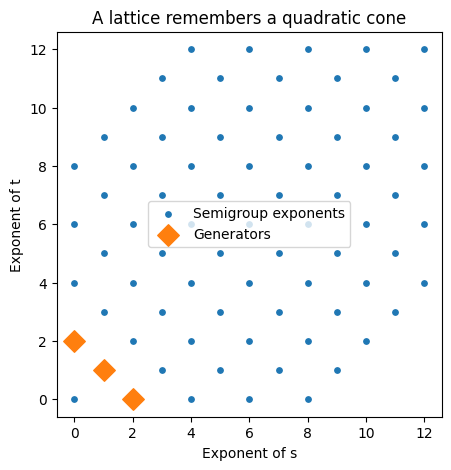

In [1]:
import sympy as sp
import matplotlib.pyplot as plt
from awa_lab.toric import generated_exponents, small_integer_relations, coordinate_ring_relation, cusp_gaps
vectors = [(2,0),(1,1),(0,2)]
points = sorted(generated_exponents(vectors,max_coefficient=4))
relations = small_integer_relations(vectors,coeff_bound=2)
print('Primitive bounded exponent relation:', relations)
print('Eliminated toric equation:', coordinate_ring_relation())
assert (1,-2,1) in relations
fig,ax=plt.subplots(figsize=(6,5))
ax.scatter([p[0] for p in points],[p[1] for p in points],s=15,label='Semigroup exponents')
ax.scatter([p[0] for p in vectors],[p[1] for p in vectors],s=120,marker='D',label='Generators')
ax.set(xlabel='Exponent of s',ylabel='Exponent of t',title='A lattice remembers a quadratic cone')
ax.set_aspect('equal'); ax.legend(); plt.show()

### Why is the surface singular?

The gradient of $F(U,V,W)=UV-W^2$ is $(V,U,-2W)$, which vanishes at the origin. The original map $(s,t)\mapsto(s^2,t^2,st)$ identifies $(s,t)$ and $(-s,-t)$, so the singular surface is a quotient by a finite symmetry group. This is an affine $A_1$ singularity.

In [2]:
U,V,W = sp.symbols('U V W')
F=U*V-W**2
print('Gradient:',[sp.diff(F,x) for x in (U,V,W)])
print('At origin:',[sp.diff(F,x).subs({U:0,V:0,W:0}) for x in (U,V,W)])
assert all(sp.diff(F,x).subs({U:0,V:0,W:0})==0 for x in (U,V,W))

Gradient: [V, U, -2*W]
At origin: [0, 0, 0]


## Experiment B · A cusp and its missing lattice point

The semigroup $S=\langle2,3\rangle\subset\mathbb N$ gives the cuspidal curve $k[t^2,t^3]\cong k[a,b]/(b^2-a^3)$. Its cone includes exponent $1$, but its semigroup does not. Geometrically, passing from $k[t^2,t^3]$ to its normalization $k[t]$ fills this hole. Indeed $t$ is integral over the smaller ring because it satisfies $z^2-t^2=0$.

**Careful:** normalization saturates the semigroup in its *group completion*, not in an arbitrary larger lattice.

In [3]:
print('Gaps in <2,3> up to 16:', cusp_gaps(16))
assert cusp_gaps(16)==[1]
t=sp.symbols('t'); a,b=sp.symbols('a b')
print('Cusp relation:', sp.factor((b**2-a**3).subs({a:t**2,b:t**3})))
assert sp.simplify((b**2-a**3).subs({a:t**2,b:t**3}))==0

Gaps in <2,3> up to 16: [1]
Cusp relation: 0


### Investigate

1. Explain why $(1,0)$ is *not* in the group generated by $(2,0),(1,1),(0,2)$, though it belongs to the ambient cone. Does this contradict normality of the quadratic cone?
2. For $S=\langle3,4\rangle$, calculate the missing degrees and use them to guess the normalization of $k[t^3,t^4]$.
3. Show that a binomial relation among lattice generators arises from an integer relation $\sum_i a_i v_i=0$, with positive and negative parts of $a$ on opposite sides.
4. The quadratic cone and the cusp are both singular. Why is the first normal and the second nonnormal?

The distinction between **ambient lattice** and **group completion** in Question 1 is essential, and is often glossed over in introductory accounts.